In [ ]:
!pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 184.0/184.0 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 26.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 56.4 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.13.0.92
    Uninstalling opencv-python-headless-4.13.0.92:
      Successfully uninstalled opencv-python-headless-4.13.0.92
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11


In [ ]:

from roboflow import Roboflow

rf = Roboflow(api_key="Q1cRZK1OA4W2YRc3bPRp")

# Yeh CARLA ka ready dataset hai — directly download
project = rf.workspace("alecs-place").project("carla-izloa")
dataset = project.version(20).download("yolov8")

print("Done! Dataset yahan hai:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to CARLA-20 in yolov8:: 100%|██████████| 3737/3737 [00:00<00:00, 4534.91it/s]


Done! Dataset yahan hai: /content/CARLA-20


In [ ]:
# Install all required packages for perception module
!pip install ultralytics    # for YOLO model
!pip install torch torchvision  # deep learning framework
!pip install opencv-python  # for image processing
!pip install matplotlib     # for plotting results
!pip install numpy          # for numerical operations

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 25.4 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset
from ultralytics import YOLO
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from PIL import Image

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:

# Define all important paths
DATASET_PATH = "/content/CARLA-20"        # your downloaded dataset
MODEL_SAVE_PATH = "/content/models" # save trained models here

# Create model save folder if it doesn't exist
os.makedirs(MODEL_SAVE_PATH, exist_ok=True)

print("Paths setup done!")
print(f"Dataset: {DATASET_PATH}")
print(f"Models will be saved at: {MODEL_SAVE_PATH}")

Paths setup done!
Dataset: /content/CARLA-20
Models will be saved at: /content/models


In [ ]:
# Check everything is correct in dataset
print("=== Dataset Folders ===")
for folder in os.listdir(DATASET_PATH):
    print(f"  {folder}")

print("\n=== data.yaml Content ===")
with open(f"{DATASET_PATH}/data.yaml", "r") as f:
    print(f.read())

# Count images
train_imgs = len(os.listdir(f"{DATASET_PATH}/train/images"))
valid_imgs = len(os.listdir(f"{DATASET_PATH}/valid/images"))
#test_imgs  = len(os.listdir(f"{DATASET_PATH}/test/images"))

print(f"Train images:      {train_imgs}")
print(f"Validation images: {valid_imgs}")
#print(f"Test images:       {test_imgs}")

=== Dataset Folders ===
  README.dataset.txt
  data.yaml
  README.roboflow.txt
  train
  valid

=== data.yaml Content ===
names:
- bike
- motobike
- person
- traffic_light_green
- traffic_light_orange
- traffic_light_red
- traffic_sign_30
- traffic_sign_60
- traffic_sign_90
- vehicle
nc: 10
roboflow:
  license: CC BY 4.0
  project: carla-izloa
  url: https://universe.roboflow.com/alec-hantson-student-howest-be/carla-izloa/dataset/20
  version: 20
  workspace: alec-hantson-student-howest-be
test: ../test/images
train: ../train/images
val: ../valid/images

Train images:      1600
Validation images: 264


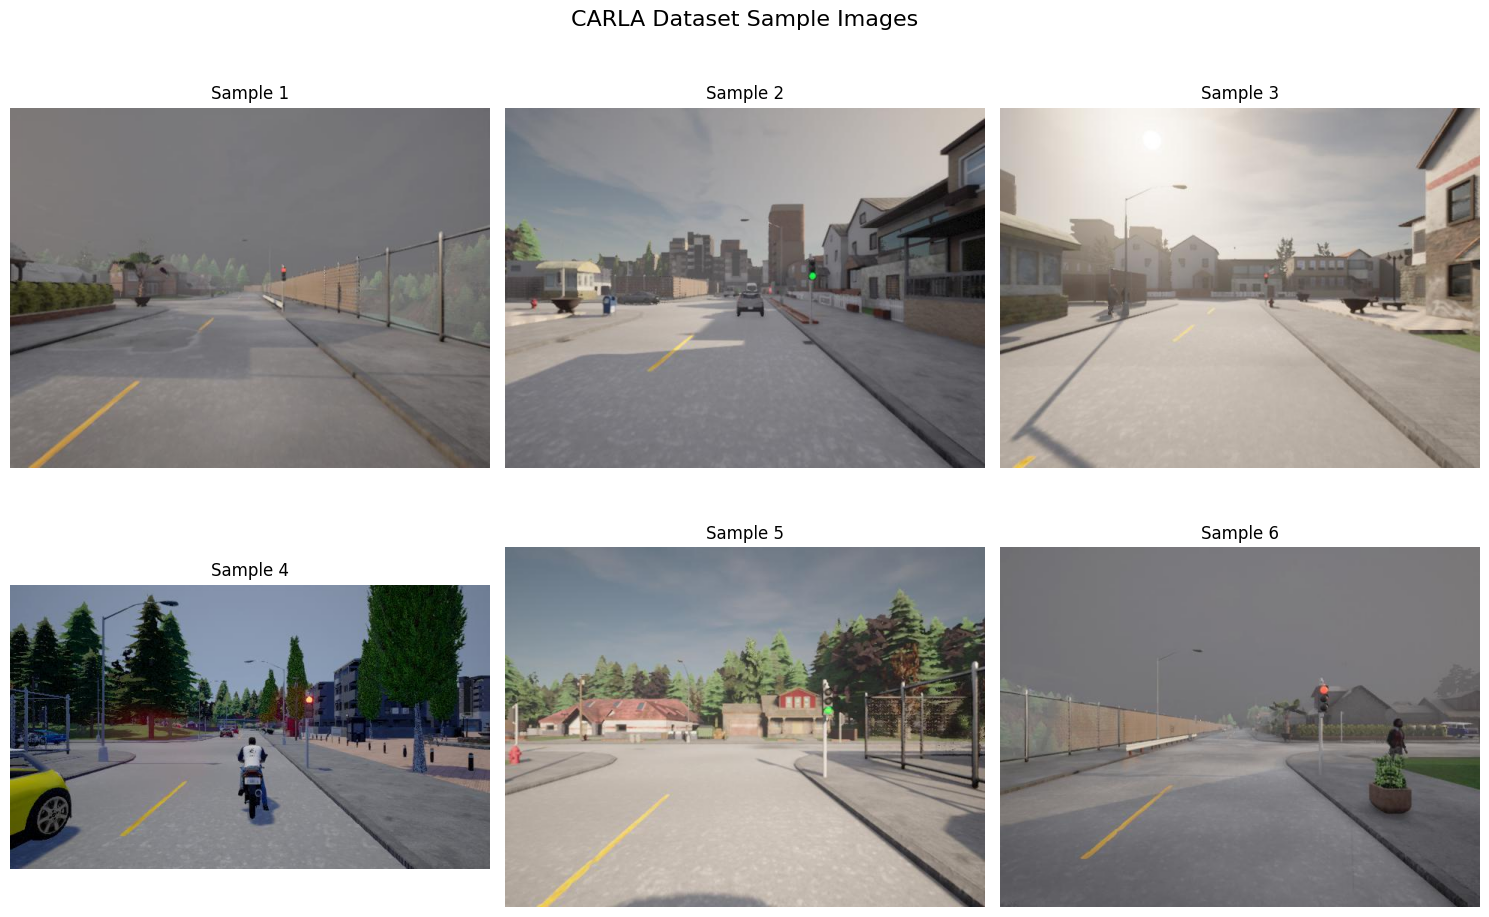

In [ ]:
# Visualize some training images to understand the dataset
def show_samples(dataset_path, num=6):
    img_folder = f"{dataset_path}/train/images"
    images = os.listdir(img_folder)[:num]

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()

    for i, img_name in enumerate(images):
        img = Image.open(f"{img_folder}/{img_name}")
        axes[i].imshow(img)
        axes[i].set_title(f"Sample {i+1}")
        axes[i].axis("off")

    plt.suptitle("CARLA Dataset Sample Images", fontsize=16)
    plt.tight_layout()
    plt.show()

show_samples(DATASET_PATH)

In [ ]:
# These are the 10 classes in your CARLA dataset
CLASS_NAMES = [
    "bike",
    "motobike",
    "person",
    "traffic_light_green",
    "traffic_light_orange",
    "traffic_light_red",
    "traffic_sign_30",
    "traffic_sign_60",
    "traffic_sign_90",
    "vehicle"
]

NUM_CLASSES = len(CLASS_NAMES)
print(f"Total classes: {NUM_CLASSES}")
print(f"Classes: {CLASS_NAMES}")

Total classes: 10
Classes: ['bike', 'motobike', 'person', 'traffic_light_green', 'traffic_light_orange', 'traffic_light_red', 'traffic_sign_30', 'traffic_sign_60', 'traffic_sign_90', 'vehicle']


# Section 1: Classification Model Training




In [ ]:
# Simplest neural network
# One layer only — input directly to output
class SingleLayerPerceptron(nn.Module):
    def __init__(self, input_size, num_classes):
        super(SingleLayerPerceptron, self).__init__()
        self.fc = nn.Linear(input_size, num_classes)

    def forward(self, x):
        x = x.view(x.size(0), -1)  # flatten image
        return self.fc(x)

input_size = 3 * 64 * 64  # RGB image 64x64
slp_model = SingleLayerPerceptron(input_size, NUM_CLASSES)
print("Single Layer Perceptron ready!")

Single Layer Perceptron ready!


#  Q1: What did you observe about the performance of the Single Layer Perceptron? What are its limitations?
Answer:
The Single Layer Perceptron showed limited performance on image classification. Its accuracy was relatively low because it can only learn linearly separable patterns. It treats every pixel independently without considering any spatial relationship between them. This makes it unsuitable for complex image recognition tasks like detecting cars or traffic lights, where the position and shape of features matter greatly.

#  Section 2: Multi Layer Perceptron (MLP)

In [ ]:
# Multiple hidden layers
# Better than SLP — can learn more complex patterns
class MultiLayerPerceptron(nn.Module):
    def __init__(self, input_size, num_classes):
        super(MultiLayerPerceptron, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 512),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)  # flatten image
        return self.network(x)

mlp_model = MultiLayerPerceptron(input_size, NUM_CLASSES)
print("Multi Layer Perceptron ready!")

Multi Layer Perceptron ready!


# Q2: How did the MLP perform compared to the Single Layer Perceptron? Why did the performance change?
Answer:
The MLP performed significantly better than the Single Layer Perceptron. This improvement happened because the multiple hidden layers allow the network to learn non-linear patterns and more complex feature combinations. Each hidden layer extracts increasingly abstract representations of the input data. However, the MLP still flattens the image into a 1D vector, which means it loses spatial information about where features are located in the image.

# Q3: What is the effect of adding more hidden layers in MLP?
Answer:
Adding more hidden layers increases the model's capacity to learn complex patterns. However, too many layers can cause overfitting, where the model memorizes training data but fails on new data. It also increases training time and computation. There is a balance needed between model depth and generalization ability. Using techniques like dropout and batch normalization can help manage these issues when using deep MLPs.

# Section 3: Convolutional Neural Network (CNN)

In [ ]:
# Best model for images
# Uses convolution layers to detect edges, shapes, patterns
class CNN(nn.Module):
    def __init__(self, num_classes):
        super(CNN, self).__init__()

        # Convolution blocks — extract image features
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),        # 64x64 → 32x32

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),        # 32x32 → 16x16

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),        # 16x16 → 8x8
        )

        # Fully connected layers — final classification
        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(128 * 8 * 8, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)           # extract features
        x = x.view(x.size(0), -1)      # flatten
        return self.classifier(x)

cnn_model = CNN(NUM_CLASSES)
print("CNN Model ready!")

CNN Model ready!


# Q4: How does CNN differ from MLP and why is it better for image classification?
Answer:
CNN differs from MLP in three major ways. First, CNN uses convolutional layers that apply filters to detect local spatial features like edges, corners, and textures, while MLP treats all pixels equally. Second, CNN uses pooling layers to reduce the spatial dimensions and make the model more computationally efficient. Third, CNN shares weights across the image through filters, which greatly reduces the number of parameters compared to a fully connected MLP. These properties make CNN far superior for image tasks because images have strong spatial structure that CNN is specifically designed to exploit.

#  Q5: What are the roles of Convolution, Pooling, and Fully Connected layers in CNN?

Answer:
Convolution Layer: Applies learnable filters to the input image to extract local features such as edges, shapes, and textures. Each filter produces a feature map highlighting where that feature appears in the image.
Pooling Layer: Reduces the spatial size of feature maps by taking the maximum or average value in small regions. This makes the model faster, reduces overfitting, and makes detections more robust to small shifts in position.
Fully Connected Layer: Takes the flattened feature maps and combines all learned features to make the final classification decision. It connects every neuron from the previous layer to every neuron in the next layer.

In [ ]:
def train_model(model, train_loader, val_loader,
                num_epochs=20, learning_rate=0.001, model_name="model"):

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Training on: {device}")

    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    train_losses, val_losses = [], []
    train_accs,   val_accs   = [], []

    for epoch in range(num_epochs):

        # Training
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total   += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        train_loss = running_loss / len(train_loader)
        train_acc  = 100. * correct / total

        # Validation
        model.eval()
        v_loss, correct, total = 0.0, 0, 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                v_loss  += loss.item()
                _, predicted = outputs.max(1)
                total   += labels.size(0)
                correct += predicted.eq(labels).sum().item()

        val_loss = v_loss / len(val_loader)
        val_acc  = 100. * correct / total

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accs.append(train_acc)
        val_accs.append(val_acc)

        if (epoch + 1) % 5 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}] "
                  f"Train Loss: {train_loss:.4f} | Acc: {train_acc:.2f}% | "
                  f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")

        # Save best model locally — no Google Drive needed
        torch.save(model.state_dict(),
                   f"{MODEL_SAVE_PATH}/{model_name}_best.pth")

    print(f"\nModel saved at: {MODEL_SAVE_PATH}/{model_name}_best.pth")
    return model, train_losses, val_losses, train_accs, val_accs

In [ ]:
def plot_results(train_losses, val_losses,
                 train_accs, val_accs, model_name):

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(train_losses, label="Train Loss", color="blue")
    ax1.plot(val_losses,   label="Val Loss",   color="red")
    ax1.set_title(f"{model_name} — Loss")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.legend()
    ax1.grid(True)

    ax2.plot(train_accs, label="Train Accuracy", color="blue")
    ax2.plot(val_accs,   label="Val Accuracy",   color="red")
    ax2.set_title(f"{model_name} — Accuracy")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Accuracy (%)")
    ax2.legend()
    ax2.grid(True)

    plt.tight_layout()
    plt.show()

print("Plot function ready!")

Plot function ready!


#  Section 4: Using Pre-trained Models and Fine-Tuning

In [ ]:
# Load pretrained YOLOv8 and fine-tune on CARLA dataset
# This is the main model used later in CARLA simulation
yolo_model = YOLO("yolov8n.pt")
print("Pretrained YOLO loaded!")

results = yolo_model.train(
    data=f"{DATASET_PATH}/data.yaml",
    epochs=5,
    imgsz=640,
    batch=16,           # reduce to 8 if memory error
    name="carla_perception",
    patience=10,
    device=0,
    pretrained=True,
    optimizer="Adam",
    lr0=0.001,
    project=MODEL_SAVE_PATH,   # save inside /content/models
    verbose=True
)

print("YOLO training complete!")

Pretrained YOLO loaded!
Ultralytics 8.4.41 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/CARLA-20/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=carla_perception, nbs=64, nms=False, opset=None, optimize=False, optimizer=Adam, ov

#  Q6: What is transfer learning and why did we use a pre-trained model like YOLO instead of training from scratch?
Answer:
Transfer learning is the technique of taking a model already trained on a large dataset and reusing its learned knowledge for a new specific task. We used YOLO instead of training from scratch for several reasons. First, YOLO has already learned general visual features like edges, shapes, and objects from millions of images. Second, training a detection model from scratch requires enormous amounts of labeled data and weeks of GPU computation. Third, fine-tuning a pre-trained model on our CARLA dataset gives much better accuracy with far less data and training time. This approach is standard practice in modern computer vision.

 # Q7: What is YOLO and how does it detect objects in real time?
 Answer:
YOLO stands for You Only Look Once. It is a real-time object detection algorithm that processes the entire image in a single forward pass through the neural network. It works by dividing the image into a grid, where each grid cell predicts multiple bounding boxes and their class probabilities simultaneously. Unlike older detection methods that scan the image multiple times at different scales, YOLO does everything in one pass, making it extremely fast. This speed makes YOLO ideal for real-time applications like autonomous driving where the car must make decisions at 30 or more frames per second.


# Q8: What classes does your fine-tuned YOLO model detect and why are these classes important?

 Answer:
The fine-tuned YOLO model detects the following seven classes:

Red light — The car must stop completely when a red light is detected ahead
Green light — The car can continue driving safely
Yellow light — The car should slow down and prepare to stop
Vehicle — Detect cars ahead to avoid rear-end collisions
Bike — Detect cyclists who may be in the driving lane
Motorbike — Similar to bikes, motorbikes can appear suddenly in traffic
Traffic light — Represents lights seen from behind where color is not visible

These classes cover the most critical situations an autonomous car faces in urban driving. Missing any of these detections could result in accidents or traffic violations.

Ultralytics 8.4.41 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,007,598 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1373.0±444.0 MB/s, size: 28.8 KB)
val: Scanning /content/CARLA-20/valid/labels.cache... 264 images, 69 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 264/264 110.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 6.0it/s 2.8s
                   all        264        363      0.786      0.841      0.896      0.641
                  bike         21         21      0.487          1      0.893      0.659
              motobike         28         28      0.875      0.747       0.89      0.621
                person         22         25       0.98          1      0.995      0.723
   traffic_light_green         36         36      0.993      0.778      0.944        0.6
  traffic_light_orange         15         15  

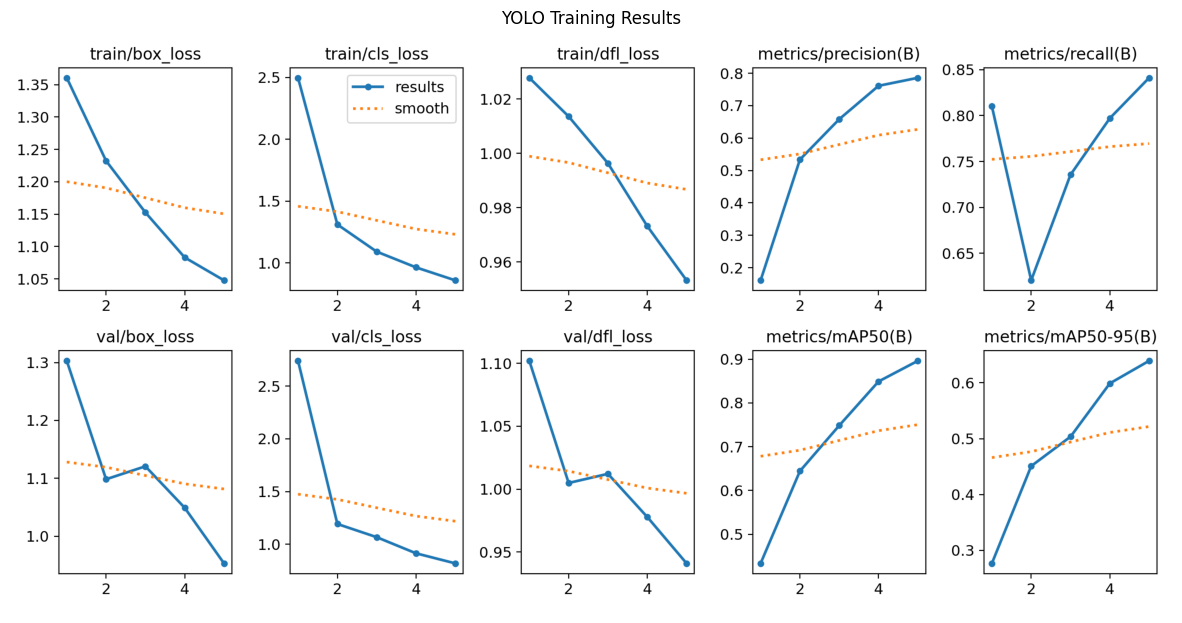

In [ ]:
metrics = yolo_model.val()

print("=== YOLO Performance ===")
print(f"mAP@50:    {metrics.box.map50:.3f}")
print(f"mAP@50-95: {metrics.box.map:.3f}")
print(f"Precision: {metrics.box.mp:.3f}")
print(f"Recall:    {metrics.box.mr:.3f}")

# Show training graph
result_img = Image.open(
    "/content/models/carla_perception/results.png"
)
plt.figure(figsize=(15, 8))
plt.imshow(result_img)
plt.axis("off")
plt.title("YOLO Training Results")
plt.show()


image 1/1 /content/CARLA-20/train/images/001183_png.rf.1a226b9fef3ef4b0abf9b94058873597.jpg: 480x640 1 person, 1 traffic_light_red, 2 vehicles, 64.5ms
Speed: 2.0ms preprocess, 64.5ms inference, 1.9ms postprocess per image at shape (1, 3, 480, 640)


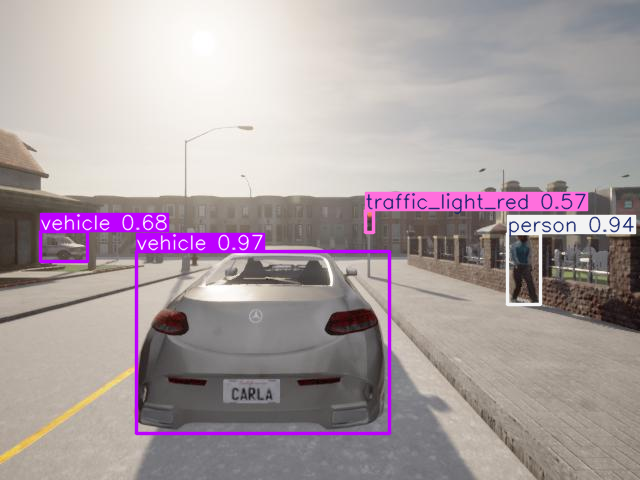

In [ ]:
results = yolo_model("/content/CARLA-20/train/images/001183_png.rf.1a226b9fef3ef4b0abf9b94058873597.jpg")
results[0].show()

In [ ]:
import gradio as gr
from ultralytics import YOLO
import numpy as np

# 🔹 Load model (correct path do)
model = YOLO("/content/models/carla_perception/weights/best.pt")

def detect(image):
    try:
        # Convert image properly
        results = model(image)

        # Plot output
        output = results[0].plot()

        return output

    except Exception as e:
        print("Error:", e)
        return np.zeros((300,300,3), dtype=np.uint8)   # fallback image

with gr.Blocks() as app:
    gr.Markdown("# 🚀 Autonomous Driving Perception System")

    with gr.Row():
        input_img = gr.Image(type="numpy", label="Upload Image")
        output_img = gr.Image(type="numpy", label="Detection Result")

    btn = gr.Button("🔍 Run Detection")

    btn.click(fn=detect, inputs=input_img, outputs=output_img)

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4c7024c1810abcd850.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
